# Dicision Tree for DDoS Detection (Multi-Class Classification)


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

## . Load Datasets

In [36]:
train_df = pd.read_csv('../datasets/TrainingSet.csv')
test_df = pd.read_csv('../datasets/TestingSet.csv')

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape:  {test_df.shape}")

Training set shape: (16000, 40)
Testing set shape:  (4000, 40)


## . Dataset Summary Report

In [37]:
def data_report(data):
    data = pd.DataFrame(
        {
            "dtype": data.dtypes.astype(str),
                    # Show the data type of each column (e.g., int, float, object)
            
                    "missing": data.isna().sum(),
                    # Count the number of missing values (NaN) in each column
            
                    "missing_%": (data.isna().mean() * 100).round(2),
                    # Calculate the percentage of missing values in each column
            
                    "unique": data.nunique(dropna=False),
                    # Count the number of unique values in each column
                    # dropna=False means that NaN is also counted as a unique value
            
                    "duplicates": data.duplicated().sum()
                    # Count the total number of duplicated rows in the dataset
         }
    )
    return data

train_report = data_report(train_df)
print(train_report)

# test_report = data_report(test_df)
# print(test_report)

train_df.describe()
# test_df.describe()

                   dtype  missing  missing_%  unique  duplicates
Header_Length    float64        0       0.00     223          94
Protocol Type      int64        0       0.00       4          94
Time_To_Live     float64        0       0.00    1583          94
Rate             float64        2       0.01   13514          94
fin_flag_number  float64        0       0.00      20          94
syn_flag_number  float64        0       0.00      48          94
rst_flag_number  float64        0       0.00      66          94
psh_flag_number  float64        0       0.00      70          94
ack_flag_number  float64        0       0.00      88          94
ece_flag_number  float64        0       0.00       4          94
cwr_flag_number  float64        0       0.00       2          94
ack_count          int64        0       0.00      83          94
syn_count          int64        0       0.00      46          94
fin_count          int64        0       0.00      19          94
rst_count          int64 

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance
count,16000.000000,16000.000000,16000.000000,15998.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,...,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,15998.000000,16000.000000,16000.000000,16000.000000,1.599800e+04
mean,21.351192,6.863937,89.309964,18288.863524,0.079604,0.148231,0.077708,0.156010,0.524924,0.000245,...,0.987577,6177.712750,96.357187,914.678375,341.216208,283.816865,341.216208,0.004493,55.287125,4.057447e+05
std,9.168019,3.826564,44.080384,32282.954849,0.261123,0.345075,0.262679,1.021511,6.927907,0.005299,...,0.044420,4869.160199,218.336392,1764.688621,557.215854,570.274487,557.215854,0.007983,44.994792,1.875141e+06
min,0.000000,0.000000,6.400000,8.342829,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.100000,66.000000,60.000000,60.000000,60.000000,0.000000,60.000000,0.000002,1.000000,0.000000e+00
25%,19.880000,6.000000,64.000000,176.670339,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,2525.500000,60.000000,60.000000,60.000000,0.000000,60.000000,0.000034,10.000000,0.000000e+00
50%,20.000000,6.000000,64.000000,7125.596414,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,...,1.000000,6000.000000,60.000000,96.000000,64.800000,3.800000,64.800000,0.000146,100.000000,1.444000e+01
75%,29.600000,6.000000,97.800000,30127.166103,0.000000,0.000000,0.000000,0.200000,0.990000,0.000000,...,1.000000,6024.000000,66.000000,1474.000000,243.075000,372.872954,243.075000,0.006436,100.000000,1.390342e+05
max,60.000000,17.000000,248.700000,665762.539683,1.000000,1.000000,1.000000,125.000000,875.000000,0.200000,...,1.000000,53675.000000,2962.000000,30474.000000,5367.500000,9533.007818,5367.500000,0.133561,100.000000,9.087824e+07


## . Handle Missing Values and Duplicates

In [38]:
# Check for missing values
missing_train = train_df.isna().sum().sum()
missing_test = test_df.isna().sum().sum()
print(f"Missing values in Train: {missing_train}, in Test: {missing_test}")
# print the columns with missing values in the training set with their datatype
missing_columns_train = train_df.columns[train_df.isna().any()].tolist()

# set the missing values to the median of the respective columns
for col in missing_columns_train:
    median_value = train_df[col].median()
    train_df[col] = train_df[col].fillna(median_value)

# check for duplicates in the training set
duplicates_train = train_df.duplicated().sum()
print(f"Duplicate rows in Train: {duplicates_train}")
# Remove duplicates rows from the training set
train_df_cleaned = train_df.drop_duplicates()

# after cleaning check the shape of the cleaned datasets

# Drop duplicate columns Variant and Tot size
train_df_cleaned = train_df_cleaned.drop(columns=['Variance', 'Tot size'])
test_df_cleaned = test_df.drop(columns=['Variance', 'Tot size'])

print(f"Cleaned Training set shape: {train_df_cleaned.shape}")
print(f"Cleaned Testing set shape:  {test_df_cleaned.shape}")

Missing values in Train: 6, in Test: 0
Duplicate rows in Train: 94
Cleaned Training set shape: (15906, 38)
Cleaned Testing set shape:  (4000, 38)


## . Data Leakage Check: the `Number` Feature
`Number` showed a correlation of ~1 with the target. It takes almost only two values (10 and 100), which looks like a dataset-collection artifact rather than real traffic behavior. It is dropped here, **before** the features are separated, so the model never sees it.

In [39]:
# 'Number' has a correlation of ~1 with Target -> likely data leakage
print(train_df_cleaned['Number'].value_counts())
print(train_df_cleaned['Number'].describe())
train_df_cleaned = train_df_cleaned.drop(columns=["Number"])
test_df_cleaned = test_df_cleaned.drop(columns=["Number"])


Number
100    7958
10     7933
1         2
6         2
9         1
68        1
17        1
48        1
3         1
8         1
76        1
79        1
96        1
53        1
43        1
Name: count, dtype: int64
count    15906.000000
mean        55.051176
std         44.995654
min          1.000000
25%         10.000000
50%        100.000000
75%        100.000000
max        100.000000
Name: Number, dtype: float64


## . Separate Features (X) and Target (y)

In [40]:
X_train = train_df_cleaned.drop(columns=['Target'])
y_train = train_df_cleaned['Target']

X_test = test_df_cleaned.drop(columns=['Target'])
y_test = test_df_cleaned['Target']

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (15906, 36), y_train shape: (15906,)
X_test shape: (4000, 36), y_test shape: (4000,)


## . Train And Evaluate Decision Tree Model with Cross Validation

In [41]:

tree_model = DecisionTreeClassifier(random_state=42)
grid = GridSearchCV(
    tree_model,
    param_grid={"max_depth": [5, 7, 10], "criterion": ["gini", "entropy"]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro",
    n_jobs=-1,
)
grid.fit(X_train, y_train)
print("Best max_depth:", grid.best_params_["max_depth"])
print("Best criterion:", grid.best_params_["criterion"])
print(f"CV F1 (train only): {grid.best_score_:.6f}")

# 3. Evaluate on test once
model = grid.best_estimator_
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.5f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
#ValueError: multi_class must be in ('ovo', 'ovr')
print("\nClassification Report:\n",
      classification_report(y_test, y_pred))
print(f"AUROC (macro, OVR): {roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro', labels=model.classes_):.6f}")

Best max_depth: 10
Best criterion: entropy
CV F1 (train only): 0.883818

Accuracy: 0.94025

Confusion Matrix:
 [[2055    0    0    0    0    0    0    0]
 [   0  276    0    0    0    0    0    0]
 [   0    0  307    0    0    0    0    0]
 [   0    0    0  240    0    0    0    0]
 [   0    0    1    0  250   40    0    0]
 [   0    0    0    0  196   92    0    0]
 [   0    0    1    0    0    0  262    0]
 [   0    1    0    0    0    0    0  279]]

Classification Report:
                          precision    recall  f1-score   support

                 BENIGN       1.00      1.00      1.00      2055
        DDOS-ICMP_FLOOD       1.00      1.00      1.00       276
      DDOS-PSHACK_FLOOD       0.99      1.00      1.00       307
       DDOS-RSTFINFLOOD       1.00      1.00      1.00       240
DDOS-SYNONYMOUSIP_FLOOD       0.56      0.86      0.68       291
         DDOS-SYN_FLOOD       0.70      0.32      0.44       288
         DDOS-TCP_FLOOD       1.00      1.00      1.00       26

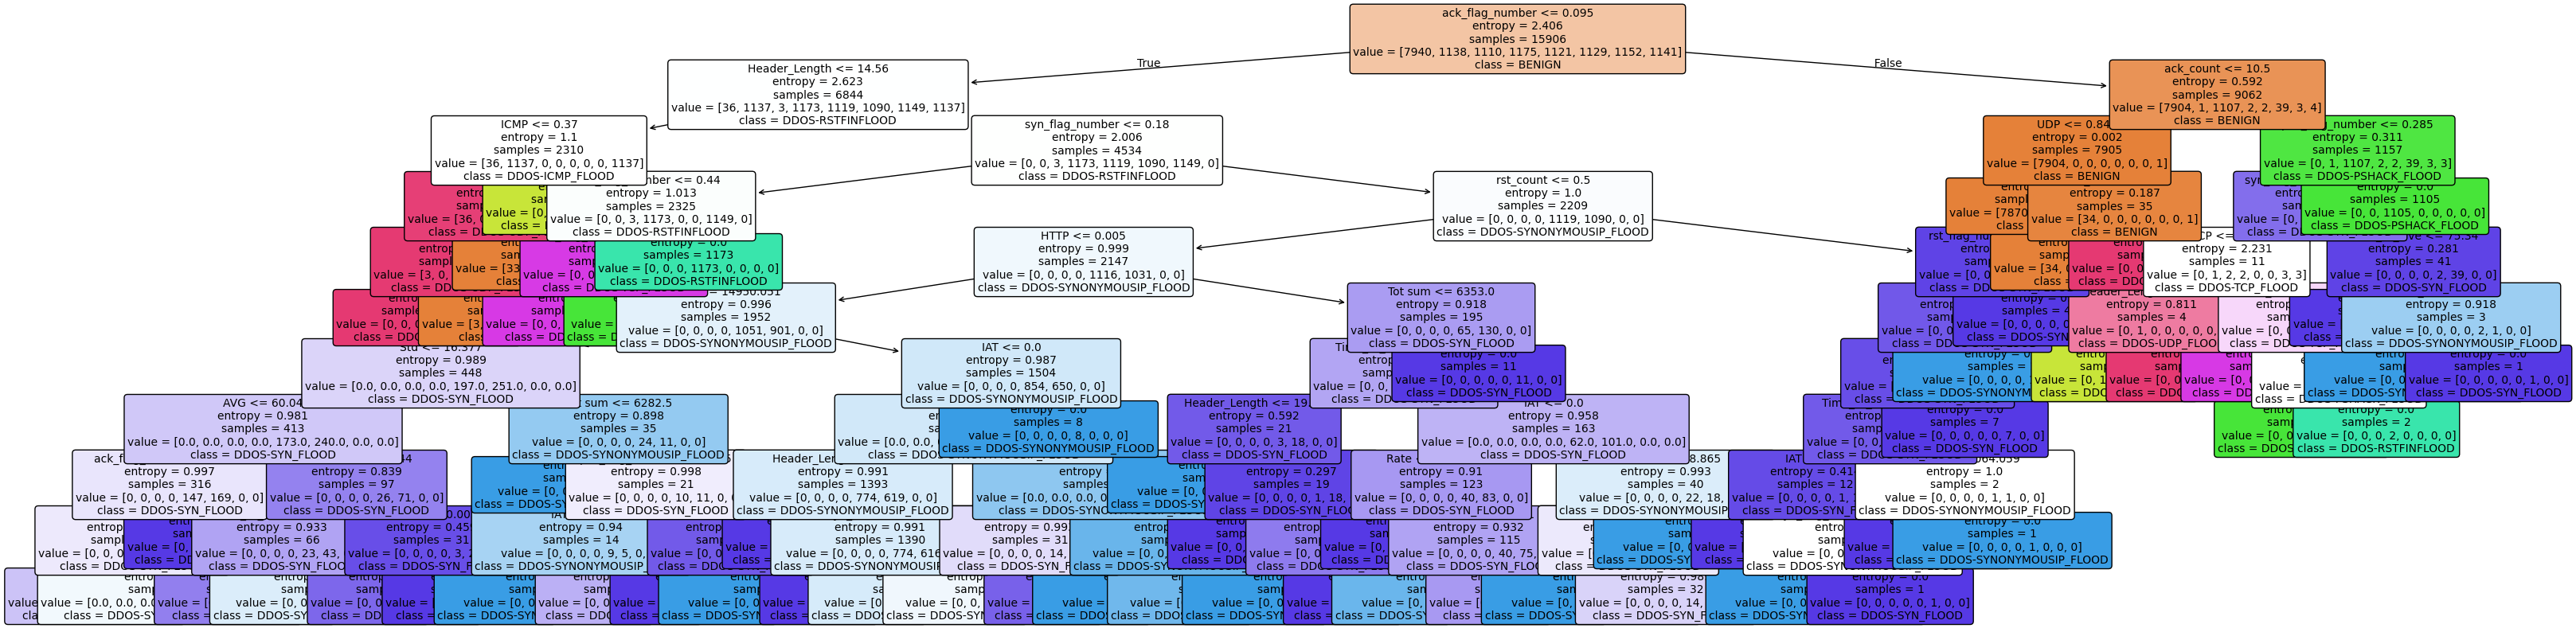

In [42]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Assume 'clf' is your trained DecisionTreeClassifier / DecisionTreeRegressor
# 'X' is your training DataFrame or matrix

plt.figure(figsize=(40, 10))
plot_tree(
    model,
    feature_names=X_train.columns,  # Pass list of feature names
    class_names=model.classes_,  # Pass list of class labels if classification
    filled=True,                        # Color-code nodes by class majority / purity
    rounded=True,                       # Draw rounded node boxes
    fontsize=10,
    max_depth=10                         # Limit depth for display if the tree is huge
)
plt.show()